Version A (original) — Linear SVM over TF-IDF features (`max_features=50000, ngram_range=(1,2)`), using scikit-learn defaults (`C=1.0, class_weight=None, loss=squared_hinge`), no hyperparameter search. This is the reference point the tuned grid-search variant (`SVM_b.ipynb`) is compared against.

In [1]:
%pip install scikit-learn pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.svm import LinearSVC

SEED = 42
np.random.seed(SEED)

In [3]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

with open(ARTIFACTS_DIR / "class_weights.json") as f:
    class_weights_raw = json.load(f)
class_weights = {int(k): v for k, v in class_weights_raw.items()}

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)

# Reuse the encoder fit in ModelPrep.ipynb - never refit here, so integer label IDs stay identical across LSTM/BERT/SVM.
y_train = label_encoder.transform(train_df["category"])
y_val = label_encoder.transform(val_df["category"])
y_test = label_encoder.transform(test_df["category"])

print("Train/val/test sizes:", len(train_df), len(val_df), len(test_df))
print("Classes:", LABEL_ORDER)

Train/val/test sizes: 224828 48178 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [4]:
MAX_FEATURES = 50000
NGRAM_RANGE = (1, 2)
MIN_DF = 2
SUBLINEAR_TF = True

vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES,
    ngram_range=NGRAM_RANGE,
    min_df=MIN_DF,
    sublinear_tf=SUBLINEAR_TF,
)

# fit on TRAIN ONLY - val/test must not leak into the vocabulary
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (224828, 50000)
X_val shape: (48178, 50000)
X_test shape: (48178, 50000)


In [5]:
USE_CLASS_WEIGHTS = False
fit_class_weight = "balanced" if USE_CLASS_WEIGHTS else None
best_c = 1.0  # scikit-learn default - no hyperparameter search in this baseline notebook

In [6]:
# Refit on train only (val was used purely for model selection above, matching the no-leakage convention already used for the TF-IDF vocabulary and the LSTM/BERT tokenizers) and time it.
start_time = time.time()
model = LinearSVC(C=best_c, class_weight=fit_class_weight, random_state=SEED)
model.fit(X_train, y_train)
train_time_sec = time.time() - start_time
print(f"Training took {train_time_sec:.1f}s")

Training took 43.8s


In [7]:
inf_start = time.time()
y_pred = model.predict(X_test)
inf_time_sec = time.time() - inf_start

report_dict = classification_report(
    y_test, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0
)
report_text = classification_report(y_test, y_pred, target_names=LABEL_ORDER, zero_division=0)
print(report_text)

cm = confusion_matrix(y_test, y_pred)
test_accuracy = report_dict["accuracy"]
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(test_df) * 1000:.3f} ms/sample")

               precision    recall  f1-score   support

     Business       0.83      0.79      0.81      6323
Entertainment       0.84      0.89      0.87     12064
       Health       0.76      0.77      0.76      4197
     Politics       0.81      0.82      0.81      6238
      Science       0.73      0.59      0.65      1609
       Sports       0.93      0.93      0.93      5854
   Technology       0.84      0.83      0.84      5827
        World       0.86      0.83      0.84      6066

     accuracy                           0.84     48178
    macro avg       0.82      0.81      0.81     48178
 weighted avg       0.84      0.84      0.84     48178

Test accuracy: 0.8381
Inference time: 0.04s total, 0.001 ms/sample


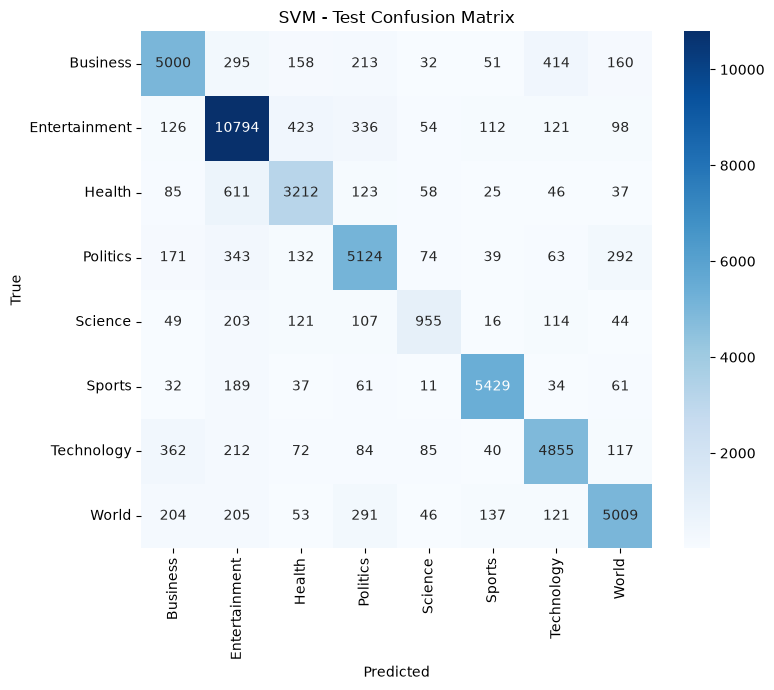

In [8]:
RESULTS_DIR = Path("../../../results/svm")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("SVM - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "SVM_a_confusion_matrix.png", dpi=150)
plt.show()

In [9]:
MODELS_DIR = Path("../../weights/svm")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

with open(MODELS_DIR / "svm_model.pkl", "wb") as f:
    pickle.dump(model, f)

with open(MODELS_DIR / "vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)

config = {
    "max_features": MAX_FEATURES,
    "ngram_range": list(NGRAM_RANGE),
    "min_df": MIN_DF,
    "sublinear_tf": SUBLINEAR_TF,
    "C": best_c,
    "class_weight": fit_class_weight,
    "loss": "squared_hinge",
    "use_class_weights": USE_CLASS_WEIGHTS,
}
with open(MODELS_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

metrics = {
    "model_family": "svm",
    "model_name": "linear-svm-tfidf",
    "run_timestamp": pd.Timestamp.now("UTC").isoformat(),
    "label_order": LABEL_ORDER,
    "config": config,
    "train": {
        "n_train": len(train_df),
        "n_val": len(val_df),
        "train_time_sec": train_time_sec,
        "epochs_trained": None,
        "history": {},
    },
    "test": {
        "n_test": len(test_df),
        "accuracy": float(test_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(test_df) * 1000,
    },
    "environment": {
        "framework": "scikit-learn",
        "framework_version": sklearn.__version__,
        "device": "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "SVM_a_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:")
print(" ", MODELS_DIR / "svm_model.pkl")
print(" ", MODELS_DIR / "vectorizer.pkl")
print(" ", MODELS_DIR / "config.json")
print(" ", RESULTS_DIR / "SVM_a_metrics.json")

Saved:
  ..\..\weights\svm\svm_model.pkl
  ..\..\weights\svm\vectorizer.pkl
  ..\..\weights\svm\config.json
  ..\..\..\results\svm\SVM_a_metrics.json
